Visualizing file: segment_000000.mat
  [Info] Applied Rotation: -23.69 degrees
----------------------------------------
Original Max Amplitude: 0.2752
Perturbed Max Amplitude: 0.3207
Signal Power (Est): 0.0422
----------------------------------------


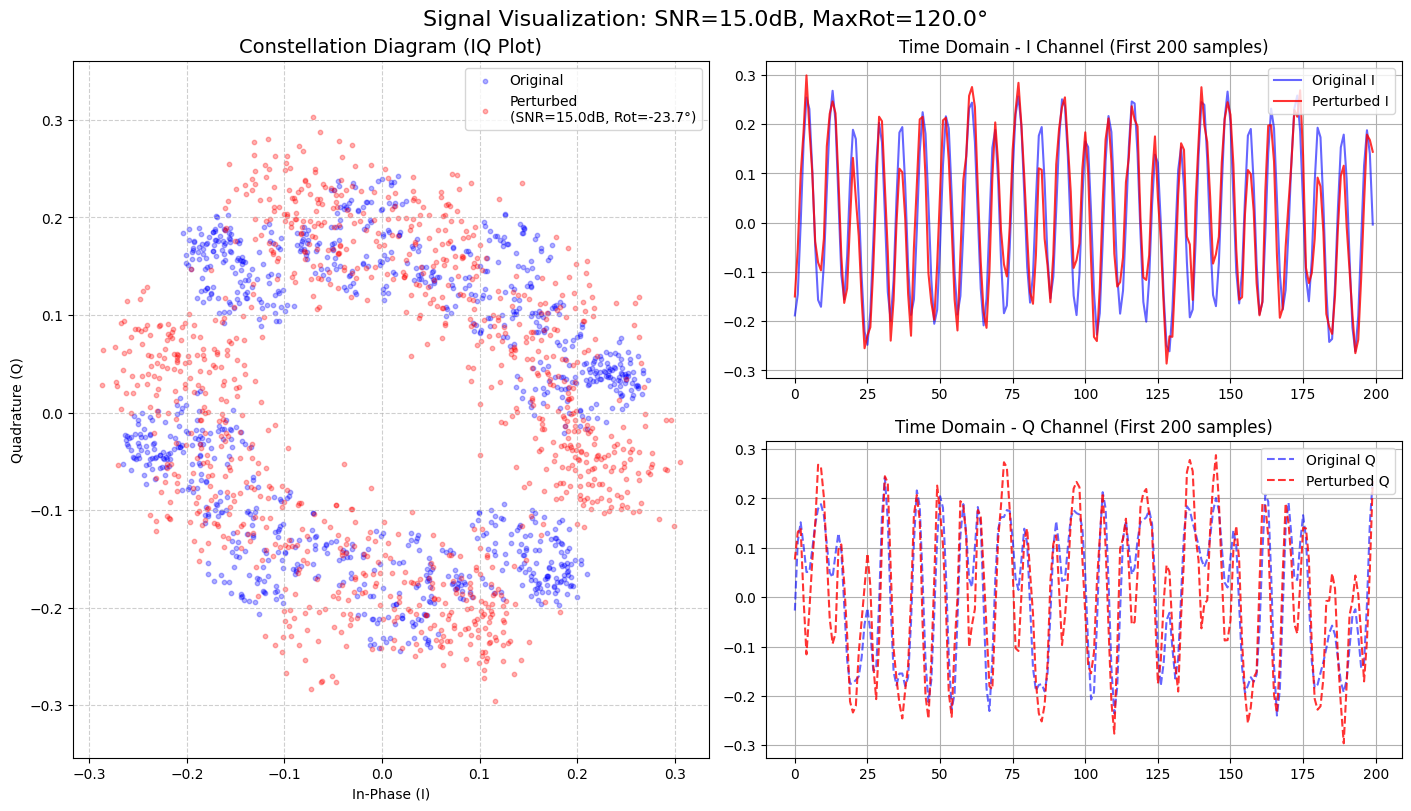

In [12]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import h5py

# ============================================================
# 1. 参数配置 (在这里修改你想观察的值)
# ============================================================
DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_2FSK/' # 数据文件夹
FILE_EXTENSION = '.mat'

# --- 核心观察参数 ---
# 场景 A: 轻松模式 (模型应该完美识别)
# TARGET_SNR_DB = 30.0    
# MAX_ROTATION_DEG = 5.0  

# 场景 B: 压力模式 (模型开始抖动) <-- 推荐观察
TARGET_SNR_DB = 15.0    
MAX_ROTATION_DEG = 120.0 

# 场景 C: 地狱模式 (模型崩溃，观察信号是如何被淹没的)
#TARGET_SNR_DB = 10.0     
#MAX_ROTATION_DEG = 60.0 

# ============================================================
# 2. 扰动函数 (与测试代码保持完全一致)
# ============================================================
def add_perturbation_snr(signal_data, max_rotation_deg, target_snr_db):
    perturbed_signal = signal_data.copy()
    
    # 提取复数
    I = perturbed_signal[0, 0, :]
    Q = perturbed_signal[0, 1, :]
    s_complex = I + 1j * Q
    
    # --- A. 旋转 ---
    rotation_angle = (np.random.rand() * 2 - 1) * max_rotation_deg
    # 打印旋转角度以便观察
    print(f"  [Info] Applied Rotation: {rotation_angle:.2f} degrees")
    s_rotated = s_complex * np.exp(1j * np.deg2rad(rotation_angle))
    
    # --- B. 噪声 ---
    sig_power = np.mean(np.abs(s_rotated)**2)
    noise_power = sig_power / (10 ** (target_snr_db / 10))
    noise_std = np.sqrt(noise_power / 2)
    
    noise = np.random.normal(0, noise_std, s_rotated.shape) + \
            1j * np.random.normal(0, noise_std, s_rotated.shape)
            
    s_final = s_rotated + noise
    
    # 还原
    perturbed_signal[0, 0, :] = np.real(s_final)
    perturbed_signal[0, 1, :] = np.imag(s_final)
    
    return perturbed_signal, rotation_angle

# ============================================================
# 3. 绘图主程序
# ============================================================
if __name__ == "__main__":
    # 1. 查找第一个文件
    search_pattern = os.path.join(DATA_FOLDER, f'*{FILE_EXTENSION}')
    files = glob.glob(search_pattern)
    
    if not files:
        print("Error: No files found.")
        exit()
        
    # 随机选一个文件，或者指定第一个
    file_path = files[0] 
    print(f"Visualizing file: {os.path.basename(file_path)}")

    # 2. 读取数据
    with h5py.File(file_path, 'r') as f:
        raw_signal = f['data_save'][:] 
    
    if raw_signal.shape == (2, 1024):
        raw_signal = raw_signal.reshape(1, 2, 1024)

    # 3. 生成扰动信号
    perturbed_signal, applied_rot = add_perturbation_snr(
        raw_signal, MAX_ROTATION_DEG, TARGET_SNR_DB
    )

    # 4. 准备绘图数据
    # 原始
    I_orig = raw_signal[0, 0, :]
    Q_orig = raw_signal[0, 1, :]
    # 扰动后
    I_pert = perturbed_signal[0, 0, :]
    Q_pert = perturbed_signal[0, 1, :]

    # ============================================================
    # 5. 开始绘制
    # ============================================================
    fig = plt.figure(figsize=(14, 8), constrained_layout=True)
    gs = fig.add_gridspec(2, 2)

    # --- 图 1: 星座图对比 (最直观) ---
    ax_const = fig.add_subplot(gs[:, 0]) # 占据左半边
    
    # 绘制原始信号 (蓝色，透明度低)
    ax_const.scatter(I_orig, Q_orig, c='blue', alpha=0.3, s=10, label='Original')
    # 绘制扰动信号 (红色，透明度低)
    ax_const.scatter(I_pert, Q_pert, c='red', alpha=0.3, s=10, label=f'Perturbed\n(SNR={TARGET_SNR_DB}dB, Rot={applied_rot:.1f}°)')
    
    ax_const.set_title("Constellation Diagram (IQ Plot)", fontsize=14)
    ax_const.set_xlabel("In-Phase (I)")
    ax_const.set_ylabel("Quadrature (Q)")
    ax_const.legend()
    ax_const.grid(True, linestyle='--', alpha=0.6)
    ax_const.axis('equal') # 保持宽高比一致，看圆还是椭圆很重要

    # --- 图 2: 时域波形 (I路) ---
    ax_time_i = fig.add_subplot(gs[0, 1]) # 右上
    # 只画前 200 个点，不然太密看不清
    subset = 200
    ax_time_i.plot(I_orig[:subset], 'b-', alpha=0.6, label='Original I')
    ax_time_i.plot(I_pert[:subset], 'r-', alpha=0.8, label='Perturbed I')
    ax_time_i.set_title(f"Time Domain - I Channel (First {subset} samples)", fontsize=12)
    ax_time_i.legend(loc='upper right')
    ax_time_i.grid(True)

    # --- 图 3: 时域波形 (Q路) ---
    ax_time_q = fig.add_subplot(gs[1, 1]) # 右下
    ax_time_q.plot(Q_orig[:subset], 'b--', alpha=0.6, label='Original Q')
    ax_time_q.plot(Q_pert[:subset], 'r--', alpha=0.8, label='Perturbed Q')
    ax_time_q.set_title(f"Time Domain - Q Channel (First {subset} samples)", fontsize=12)
    ax_time_q.legend(loc='upper right')
    ax_time_q.grid(True)

    # 打印一些统计信息
    print("-" * 40)
    print(f"Original Max Amplitude: {np.max(np.abs(I_orig + 1j*Q_orig)):.4f}")
    print(f"Perturbed Max Amplitude: {np.max(np.abs(I_pert + 1j*Q_pert)):.4f}")
    print(f"Signal Power (Est): {np.mean(np.abs(I_orig + 1j*Q_orig)**2):.4f}")
    print("-" * 40)

    plt.suptitle(f"Signal Visualization: SNR={TARGET_SNR_DB}dB, MaxRot={MAX_ROTATION_DEG}°", fontsize=16)
    plt.show()